# EDA
exploratory data analysis, find the following relations
- posting time, waiting time
- words in tweet, waiting time

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cases = pd.read_pickle("../data/cases.pkl")
print(cases.shape)
cases.head()

(209868, 10)


,case_id,brand,customer_id,customer_text,created_at,is_first_tweet,reply_tweet_id,reply_text,reply_at,response_minutes
0,193661,AppleSupport,161535,@AppleSupport Yes I’m able to open safari but ...,2017-10-04 00:03:07+00:00,False,193660,@161535 Understood! Can you tell us the versio...,2017-10-04 00:59:51+00:00,56.733333
1,1286995,AmazonHelp,421025,"@AmazonHelp I can't explain in 140 c, that's w...",2017-10-04 00:04:13+00:00,False,1286994,@421025 You can send us a direct message if yo...,2017-10-04 00:12:31+00:00,8.300000
2,243032,AppleSupport,173714,Apple Podcast is not played continuously on #i...,2017-10-04 00:07:40+00:00,True,243030,@173714 Let's see if we can keep your podcasts...,2017-10-04 00:36:31+00:00,28.850000
3,387506,AppleSupport,207722,@AppleSupport I did that yesterday.,2017-10-04 00:15:29+00:00,False,387504,"@207722 Which iPhone do you have, and what's t...",2017-10-04 00:37:54+00:00,22.416667
4,1286993,AmazonHelp,421025,"@AmazonHelp I found the email, never mind.",2017-10-04 00:24:40+00:00,False,1286992,@421025 No problem! Anytime you need assistanc...,2017-10-04 00:33:30+00:00,8.833333


In [3]:
# created_at is stored in UTC; convert to US Eastern Time so "morning" and "night" match local hours
# tz_convert also handles the DST change on Nov 5, 2017 automatically
cases["local_time"] = cases["created_at"].dt.tz_convert("America/New_York")

cases["hour"] = cases["local_time"].dt.hour            # hour of day, 0-23
cases["weekday"] = cases["local_time"].dt.day_name()   # Monday, Tuesday, ...

# Check the new columns
cases[["created_at", "local_time", "hour", "weekday", "response_minutes"]].head()

,created_at,local_time,hour,weekday,response_minutes
0,2017-10-04 00:03:07+00:00,2017-10-03 20:03:07-04:00,20,Tuesday,56.733333
1,2017-10-04 00:04:13+00:00,2017-10-03 20:04:13-04:00,20,Tuesday,8.300000
2,2017-10-04 00:07:40+00:00,2017-10-03 20:07:40-04:00,20,Tuesday,28.850000
3,2017-10-04 00:15:29+00:00,2017-10-03 20:15:29-04:00,20,Tuesday,22.416667
4,2017-10-04 00:24:40+00:00,2017-10-03 20:24:40-04:00,20,Tuesday,8.833333


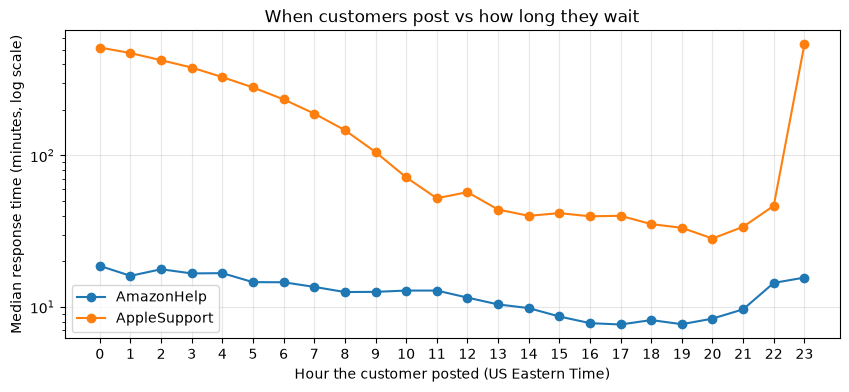

In [4]:
# Median response time for each (hour, brand) pair; median is robust to very long waits
hourly = cases.groupby(["hour", "brand"])["response_minutes"].median().unstack()

plt.figure(figsize=(10, 4))
for brand in hourly.columns:
    plt.plot(hourly.index, hourly[brand], marker="o", label=brand)
plt.yscale("log")   # log scale so both brands fit on one chart
plt.xticks(range(24))
plt.xlabel("Hour the customer posted (US Eastern Time)")
plt.ylabel("Median response time (minutes, log scale)")
plt.title("When customers post vs how long they wait")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [5]:
def time_of_day(h):
    """Map an hour (0-23) to one of four time-of-day buckets."""
    if 6 <= h < 12:
        return "Morning (6-12)"
    elif 12 <= h < 18:
        return "Afternoon (12-18)"
    elif 18 <= h < 24:
        return "Evening (18-24)"
    else:
        return "Night (0-6)"

cases["time_of_day"] = cases["hour"].apply(time_of_day)

# Number of cases, median and mean wait for each brand and time bucket
cases.groupby(["brand", "time_of_day"])["response_minutes"].agg(["count", "median", "mean"]).round(1)

count  median   mean
brand        time_of_day                            
AmazonHelp   Afternoon (12-18)  30798     9.3   15.7
             Evening (18-24)    19860    10.1   16.5
             Morning (6-12)     34406    13.1   18.3
             Night (0-6)        26466    16.5   23.4
AppleSupport Afternoon (12-18)  35395    44.2   69.6
             Evening (18-24)    26969    41.6  125.1
             Morning (6-12)     23034   118.0  131.9
             Night (0-6)        12940   436.9  428.8

In [6]:
# Median response time by weekday, in calendar order
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
cases.groupby(["weekday", "brand"])["response_minutes"].median().unstack().reindex(days).round(1)

brand,AmazonHelp,AppleSupport
weekday,,
Monday,13.4,48.0
Tuesday,12.4,41.3
Wednesday,11.7,40.2
Thursday,11.5,65.1
Friday,11.3,159.3
Saturday,12.1,168.1
Sunday,12.7,95.7


In [7]:
# Check whether Apple's weekday pattern is driven by the iOS 11.1 bug period (Oct 31 - Nov 9, 2017)
apple = cases[cases["brand"] == "AppleSupport"]
in_bug = (apple["local_time"] >= "2017-10-31") & (apple["local_time"] < "2017-11-10")

days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pd.DataFrame({
    "All days": apple.groupby("weekday")["response_minutes"].median(),
    "Without bug period": apple[~in_bug].groupby("weekday")["response_minutes"].median(),
}).reindex(days).round(1)

,All days,Without bug period
weekday,,
Monday,48.0,24.4
Tuesday,41.3,28.8
Wednesday,40.2,36.1
Thursday,65.1,54.3
Friday,159.3,113.3
Saturday,168.1,117.5
Sunday,95.7,52.9


### Findings: posting time

- **AmazonHelp replies fast at every hour.** The median wait stays between about 8 and 19 minutes all day. Night posts (0-6) wait a little longer (16.5 min) than afternoon posts (9.3 min), but the gap is small. Amazon seems to staff support around the clock.
- **AppleSupport depends strongly on posting time.** Afternoon and evening posts wait about 40-45 minutes (median), but night posts wait about 437 minutes (over 7 hours).
- The Apple curve jumps at **23:00 ET** and slowly falls until about 11:00. This suggests Apple's support team mostly stops replying late at night, so these tweets wait until the next morning.
- By weekday, Amazon is flat (11-13 min median). Apple is slower from Thursday to Saturday (65-168 min) than Monday to Wednesday (40-48 min).
- Part of this comes from the iOS 11.1 bug period (Oct 31 - Nov 9), which made Apple slower overall. But even after removing those days, Friday and Saturday are still much slower (about 115 min vs 25-35 min on Monday to Wednesday), so the weekly pattern is not only caused by the bug.
- The data covers only about 9 weeks, so each weekday has only about 9 days. One very busy day can move a weekday's median a lot.

**Limitation:** we do not know each customer's real time zone, so we use US Eastern Time for everyone.